<a href="https://colab.research.google.com/github/kfartem434-png/MN_Kapusta/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9A%D0%B0%D0%BF%D1%83%D1%81%D1%82%D0%B0_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_STATE = 42

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris_frame = load_iris(as_frame=True)
features = iris_frame.data.copy()
display(features.head(5))
print(list(features.columns))
display(features.shape)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


(150, 4)

**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

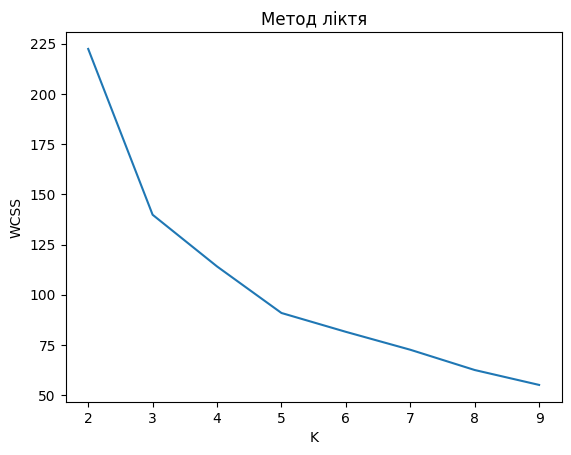

In [ ]:
X_iris = StandardScaler().fit_transform(features)
y_iris_true = iris_frame.target.copy()

km_params = {
    "n_init": 10,
    "random_state": RANDOM_STATE
}
wcss = []
for k in range(2,10):
  model = KMeans(n_clusters=k,**km_params)
  labels_km = model.fit_predict(X_iris)
  wcss.append(model.inertia_)

plt.plot(range(2,10),wcss)
plt.title("Метод ліктя")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.show()

In [ ]:
optimal_k_knee = 3

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

Найвищий середній силует: 2


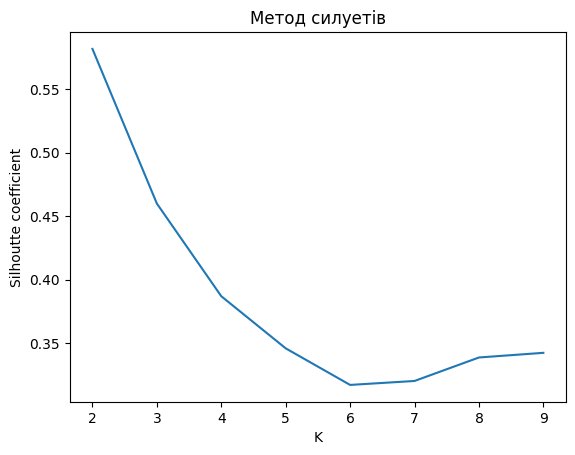

In [ ]:
scores = dict()
for k in range(2,10):
  labels_km = KMeans(n_clusters=k,**km_params).fit_predict(X_iris)
  scores[k] = silhouette_score(X_iris,labels_km)

opimal_k_silhoutte = max(scores,key=scores.get)
print('Найвищий середній силует:', opimal_k_silhoutte)

plt.plot(range(2,10),scores.values())
plt.title("Метод силуетів")
plt.xlabel("K")
plt.ylabel("Silhoutte coefficient")
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

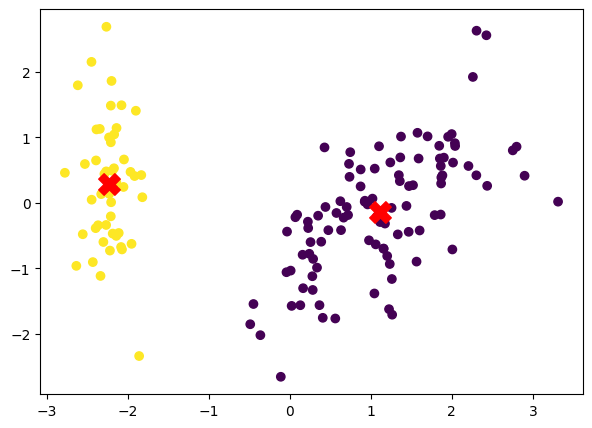

In [ ]:
model_km = KMeans(n_clusters=2,**km_params)
labels_km = model_km.fit_predict(X_iris)

pca_iris = PCA(n_components=2).fit(X_iris)
X_iris_2d = pca_iris.transform(X_iris)
iris_centroids = pca_iris.transform(model_km.cluster_centers_)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_iris_2d[:,0], X_iris_2d[:,1], c=labels_km)
ax.scatter(iris_centroids[:,0],iris_centroids[:,1],color="red",marker="X",s=240)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Метод ліктя повернув значення K = 3, в порівняні, метод силуетів повернув значення K = 2, тобто на один кластер меньше. Метод силуетів обрав 2 кластери, так як датасет визначає дві опуклі групи з середнім значенням відокремлення, що також можна побачити на графіку вище.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print(list(df.columns))

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
df.isna().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print("Повні дуплікати:",df.duplicated().sum())
print("Дуплікати StudentID:",df["StudentID"].duplicated().sum())

Повні дуплікати: 0
Дуплікати StudentID: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
ids = df["StudentID"]
X = df.drop(columns=["StudentID","GradeClass"])
y = df["GradeClass"]

X_train, X_test, y_train, y_test = train_test_split(
  X,y,test_size=20,random_state=RANDOM_STATE,stratify=y
)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
random_forest_params_grid = {
  "max_depth": [4,5,6,7,8],
  "min_samples_leaf": [3,5,7]
}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
random_forest_search = GridSearchCV(
  RandomForestClassifier(random_state=RANDOM_STATE),
  random_forest_params_grid,
  cv=cv,
  scoring="f1_macro"
)
random_forest_search.fit(X_train, y_train)

print("Найкращі гіперпараметри:", random_forest_search.best_params_)
print("CV F1 macro:", random_forest_search.best_score_)
print("CV accuracy:",accuracy_score(y_test,random_forest_search.predict(X_test)))

Найкращі гіперпараметри: {'max_depth': 8, 'min_samples_leaf': 3}
CV F1 macro: 0.8135837204660659
CV accuracy: 0.85


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
logistic_regression_params_grid = {
  "max_iter": [1000,2000,4000,8000],
}

logistic_regression_search = GridSearchCV(
  LogisticRegression(random_state=RANDOM_STATE),
  logistic_regression_params_grid,
  cv=cv,
  scoring="f1_macro"
)
logistic_regression_search.fit(X_train,y_train)

print("Найкращі гіперпараметри:", logistic_regression_search.best_params_)
print("CV F1 macro:", logistic_regression_search.best_score_)
print("CV accuracy:",accuracy_score(y_test,logistic_regression_search.predict(X_test)))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Найкращі гіперпараметри: {'max_iter': 2000}
CV F1 macro: 0.5967647487765226
CV accuracy: 0.8


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm_params_grid = {
  "C": [0.1,1,2],
  "degree": [2,3,4],
  "gamma": [0.01,0.1,0.5]
}

svm_search = GridSearchCV(
  SVC(kernel="rbf",random_state=RANDOM_STATE),
  svm_params_grid,
  cv=cv,
  scoring="f1_macro"
)
svm_search.fit(X_train,y_train)

print("Найкращі гіперпараметри:", svm_search.best_params_)
print("CV F1 macro:", svm_search.best_score_)
print("CV accuracy:",accuracy_score(y_test,svm_search.predict(X_test)))

Найкращі гіперпараметри: {'C': 2, 'degree': 2, 'gamma': 0.1}
CV F1 macro: 0.6055921968822608
CV accuracy: 0.75


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
classification_models = dict()
classification_models["random_forest"] = accuracy_score(y_test,random_forest_search.predict(X_test))
classification_models["logistic_regression"] = accuracy_score(y_test,logistic_regression_search.predict(X_test))
classification_models["svm"] = accuracy_score(y_test,svm_search.predict(X_test))
pd.DataFrame(classification_models,index=["accuracy",])

,random_forest,logistic_regression,svm
accuracy,0.85,0.8,0.75


In [ ]:
best_model = random_forest_search
print(classification_report(y_test,best_model.predict(X_test)))

              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00         1
         1.0       0.50      0.50      0.50         2
         2.0       0.75      1.00      0.86         3
         3.0       1.00      0.75      0.86         4
         4.0       0.91      1.00      0.95        10

    accuracy                           0.85        20
   macro avg       0.63      0.65      0.63        20
weighted avg       0.82      0.85      0.83        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

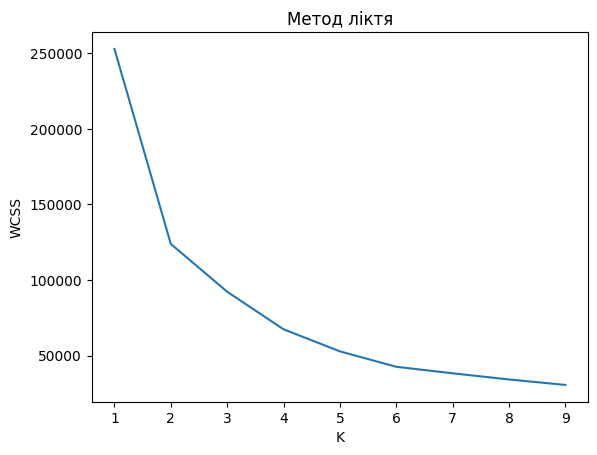

In [ ]:
wcss = []
for k in range(1,10):
  model = KMeans(n_clusters=k,**km_params)
  labels_km = model.fit_predict(X[["Age","StudyTimeWeekly","Absences","GPA"]])
  wcss.append(model.inertia_)

plt.plot(range(1,10),wcss)
plt.title("Метод ліктя")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.show()

In [ ]:
optimal_student_k_knee = 4

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

Найвищий середній силует: 2


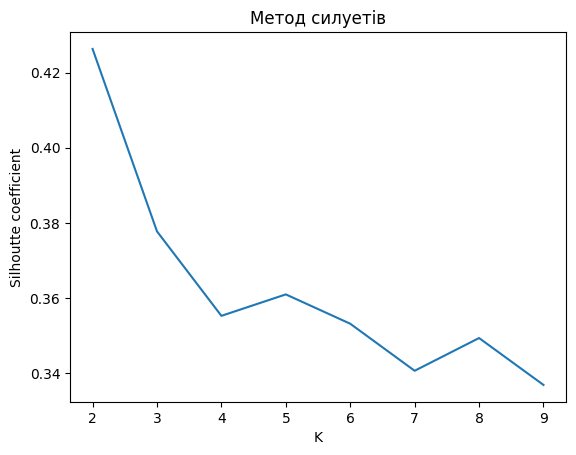

In [ ]:
scores = dict()
for k in range(2,10):
  labels_km = KMeans(n_clusters=k,**km_params).fit_predict(X[["Age","StudyTimeWeekly","Absences","GPA"]])
  scores[k] = silhouette_score(X[["Age","StudyTimeWeekly","Absences","GPA"]],labels_km)

opimal_student_k_silhoutte = max(scores,key=scores.get)
print('Найвищий середній силует:', opimal_student_k_silhoutte)

plt.plot(range(2,10),scores.values())
plt.title("Метод силуетів")
plt.xlabel("K")
plt.ylabel("Silhoutte coefficient")
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
!pip install kneed
!pip install yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
X_pca = df.drop(columns=["StudentID","GradeClass"])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
X_pca_scaled = StandardScaler().fit_transform(X_pca)
pca_model = PCA().fit(X_pca_scaled)
print(pca_model.explained_variance_)

[1.98292746 1.119945   1.07527453 1.04977619 1.02285488 1.01352344
 0.9924176  0.98846964 0.9677205  0.95977394 0.93220129 0.87736012
 0.02319247]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

0


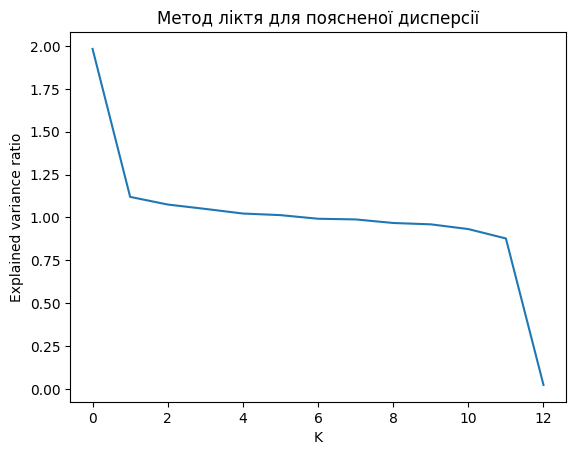

In [ ]:
optimal_pca_k_knee = KneeLocator(
  np.arange(len(pca_model.explained_variance_ratio_)),
  pca_model.explained_variance_
).elbow
print(optimal_pca_k_knee)

plt.plot(
  np.arange(len(pca_model.explained_variance_ratio_)),
  pca_model.explained_variance_
)
plt.title("Метод ліктя для поясненої дисперсії")
plt.xlabel("K")
plt.ylabel("Explained variance ratio")
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

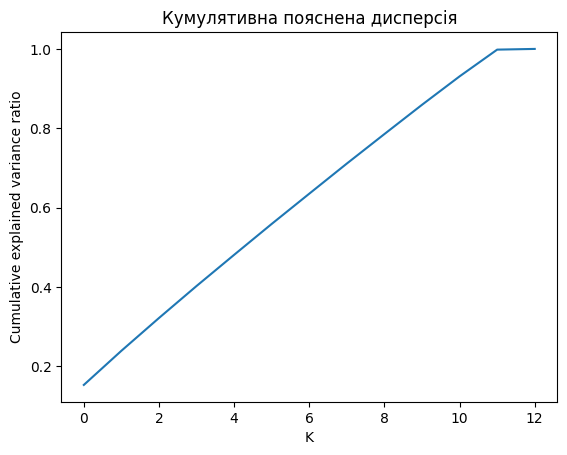

In [ ]:
cumulative_vaiance = pd.Series(pca_model.explained_variance_ratio_).expanding().sum()

plt.plot(
  np.arange(len(pca_model.explained_variance_ratio_)),
  cumulative_vaiance
)
plt.title("Кумулятивна пояснена дисперсія")
plt.xlabel("K")
plt.ylabel("Cumulative explained variance ratio")
plt.show()

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

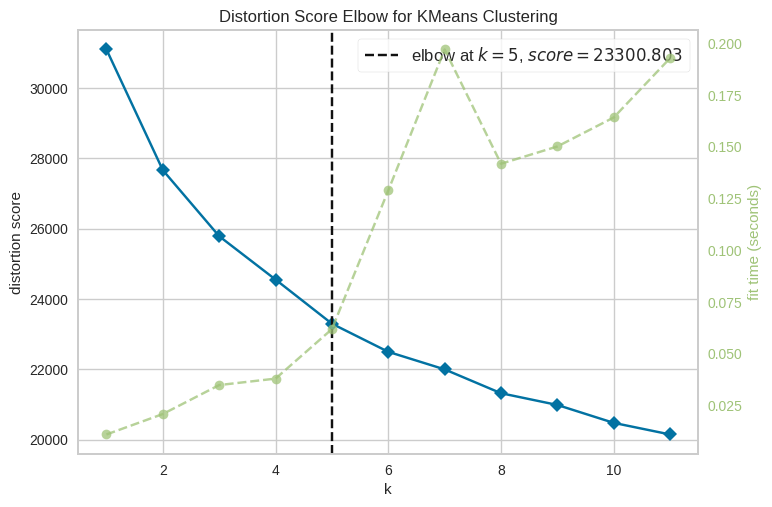

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
visualizer = KElbowVisualizer(KMeans(**km_params),k=(1,12))

visualizer.fit(X_pca_scaled)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.